# 03.1 - Fourier analysis of the interlaced acquisition

Everything here happens in the **partial Fourier transform**: one transform over the two
scan axes, none over the detector. That mixed representation
$\hat I(\mathbf Q, \mathbf k)$ is where direct ptychography lives - for each scan frequency
$\mathbf Q$ it hands back a whole detector plane, and the interference between the central
bright-field disc and the two discs displaced by $\pm\mathbf q\lambda$ carries the object
phase.

## The layout convention: no fftshift anywhere

Every map in this notebook is the **raw, unshifted** transform:

* **$\mathbf Q = 0$ of the structural channel sits at the four corners.**
* **The interlacing carrier - and therefore the excitation - sits at the dead centre**,
  because for an even-length scan the array centre $(N/2, N/2)$ *is* the Nyquist corner.

Nothing is rolled or shifted, so the excitation is where you look for it: the middle.

## The one subtlety this forces

The SSB sidelobe geometry depends on the **object** frequency, and the two channels carry
different object frequencies at the same array index. Near the corners the bin holds
structural signal at $\mathbf q = \mathbf Q$; near the centre it holds the demodulated
excitation at $\mathbf q = \mathbf Q - \mathbf Q_{\rm carrier}$. At the centre itself
$|\mathbf Q| = 7.07\ \mathrm{\AA^{-1}}$, which is far outside the
$1.233\ \mathrm{\AA^{-1}}$ probe bandwidth - so a mask built from the raw $\mathbf Q$ is
*empty* there and every sidelobe metric reads zero.

So each bin is given the object frequency of whichever channel's origin it is nearer to.
The scan is 4.05x oversampled, so the two channels are separated by far more than the
bandwidth and the assignment is unambiguous everywhere either one carries anything.

**Dataset** the same `focus0_s010` pair as `03` (C10 = 0, 30 mrad, 0.10 A step).


In [1]:
%load_ext autoreload
%autoreload 2

import json
import sys
import time
from collections import namedtuple
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.patches import Circle, Rectangle
from scipy.stats import binned_statistic

NOTEBOOK_DIR = Path.cwd()
DATA_DIR = NOTEBOOK_DIR / "data"
RESULTS_DIR = NOTEBOOK_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)
sys.path.insert(0, str(NOTEBOOK_DIR.parent))
import method_wrappers as mw
from quantem.core import config

config.set_device(0)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

OVERRIDES = {"defocus_C10_ang": 0.0, "convergence_semiangle_mrad": 30.0, "step_ang": 0.1}
PREFIX = "focus0_s010"
with open(DATA_DIR / "ideal_geometry.json") as handle:
    BASE_META = json.load(handle)
BASE_PATH, EXC_PATH, META = mw.ensure_dataset(DATA_DIR, BASE_META, OVERRIDES, prefix=PREFIX)

ACC_V      = META["beam"]["accelerating_voltage_eV"]
ALPHA_MRAD = META["beam"]["convergence_semiangle_mrad"]
WAVELENGTH = META["beam"]["wavelength_ang"]
scan_step  = META["scan"]["step_ang"]
n_scan     = META["scan"]["n_positions_per_side"]
n_det      = META["detector"]["n_pixels_binned"]
det_pitch  = META["detector"]["binned_pitch_mrad"]
F_NY       = 1.0 / (2 * scan_step)
BANDWIDTH  = META["probe"]["bandwidth_inv_ang"]
N_DET2     = n_det * n_det
CARRIER_IDX = (n_scan // 2, n_scan // 2)

print(f"scan {n_scan}^2 at {scan_step} A   f_Nyquist {F_NY:.4f} 1/A   "
      f"bandwidth {BANDWIDTH:.4f} 1/A  ({F_NY/BANDWIDTH:.2f}x oversampled)")
print(f"detector {n_det}^2 at {det_pitch:.5f} mrad/px, {N_DET2:,} pixels")
print(f"carrier at array index {CARRIER_IDX} - the CENTRE, no shift applied")


cuda:0
  cached: focus0_s010_base_noiseless.npy, focus0_s010_excited_noiseless.npy  (C10 0.0 A, 30.0 mrad, 300^2 at 0.1 A)
scan 300^2 at 0.1 A   f_Nyquist 5.0000 1/A   bandwidth 1.2330 1/A  (4.06x oversampled)
detector 192^2 at 0.54657 mrad/px, 36,864 pixels
carrier at array index (150, 150) - the CENTRE, no shift applied


## Loading and interlacing

One cube is 13.3 GB. Nothing holds more than two at a time: the noiseless interlaced cube
(which is also the matched filter's reference) and one reusable buffer that every dosed
measurement is written into, in scan-row blocks.


In [2]:
src_off = np.load(BASE_PATH, mmap_mode="r")
src_on = np.load(EXC_PATH, mmap_mode="r")

ROWS = 16
SEED = 0
SEED_STREAM = {"base": 0, "excited": 10_000, "interlaced": 20_000}

t0 = time.time()
NOISELESS_INT = mw.build_dosed_cube(src_off, src_on, None, scan_step, rows=ROWS)
BUF = np.empty(src_off.shape, dtype=np.float32)
print(f"noiseless interlaced {NOISELESS_INT.shape} {NOISELESS_INT.nbytes/1e9:.1f} GB "
      f"+ one reusable buffer of the same size ({time.time()-t0:.0f} s)")

REF = {"base": src_off, "excited": src_on, "interlaced": NOISELESS_INT}
SOURCES = {"base": (src_off, None), "excited": (src_on, None),
           "interlaced": (src_off, src_on)}


def measured(name, dose):
    """The dosed cube for one dataset, written into the shared buffer."""
    if dose is None:
        return REF[name]
    off, on = SOURCES[name]
    return mw.build_dosed_cube(off, on, dose, scan_step, out=BUF, rows=ROWS,
                               seed=SEED + SEED_STREAM[name])


def rss_gb():
    for line in open("/proc/self/status"):
        if line.startswith("VmRSS:"):
            return int(line.split()[1]) / 1e6
    return float("nan")


noiseless interlaced (300, 300, 192, 192) 13.3 GB + one reusable buffer of the same size (7 s)


## The scan-frequency grids, and the per-bin object frequency

Three grids, all on the same unshifted array:

* `QX_main`, `QY_main` - `fftfreq`, zero at the corners. The structural channel.
* `QX_car`, `QY_car` - zero at the centre. The demodulated carrier channel.
* `QX_eff`, `QY_eff` - whichever of the two that bin is nearer to. This is what the
  sidelobe masks are built from.

`R_car` doubles as the ring used later to pick out the excitation's band.


In [3]:
dQ = 1.0 / (n_scan * scan_step)
f_main = np.fft.fftfreq(n_scan, d=scan_step)          # 0 at index 0
f_car = (np.arange(n_scan) - n_scan / 2) * dQ         # 0 at index n_scan//2

QX_main, QY_main = np.meshgrid(f_main, f_main, indexing="ij")
QX_car, QY_car = np.meshgrid(f_car, f_car, indexing="ij")
R_main = np.hypot(QX_main, QY_main)
R_car = np.hypot(QX_car, QY_car)

USE_MAIN = R_main <= R_car
QX_eff = np.where(USE_MAIN, QX_main, QX_car)
QY_eff = np.where(USE_MAIN, QY_main, QY_car)
R_eff = np.hypot(QX_eff, QY_eff)

print(f"dQ = {dQ:.4f} 1/A")
print(f"bins assigned to the structural channel: {100*USE_MAIN.mean():.1f}%, "
      f"to the carrier channel: {100*(~USE_MAIN).mean():.1f}%")
print(f"max |q_eff| anywhere = {R_eff.max():.3f} 1/A  (bandwidth {BANDWIDTH:.3f}); "
      f"bins inside the bandwidth: {100*(R_eff <= BANDWIDTH).mean():.1f}%")

# detector axes, mrad, DC at the centre (the stored patterns are already centred)
q_axis_mrad = (np.arange(n_det) - n_det / 2 + 0.5) * det_pitch
KX_np, KY_np = np.meshgrid(q_axis_mrad, q_axis_mrad, indexing="ij")


dQ = 0.0333 1/A
bins assigned to the structural channel: 50.3%, to the carrier channel: 49.7%
max |q_eff| anywhere = 5.000 1/A  (bandwidth 1.233); bins inside the bandwidth: 9.5%


## The metrics

Each reduction collapses the detector axes of $\hat I(\mathbf Q, \mathbf k)$ to one number
per scan frequency, giving an $(n_{\rm scan}, n_{\rm scan})$ map in the unshifted layout.

They are applied one detector slab at a time - the full transform is
$300^2\times192^2$ complex64 = 26.5 GB - so each entry is a function of a slab plus a
context, together with how its partial results combine across slabs. Everything here is
separable over detector pixels, so that is exact.

* `max`, `sum`, `mean` - the naive reductions. `sum` is the statistic that is wrong by
  $\sqrt{N_{\rm det}} = 192$, kept so the figures show it being wrong.
* `sum_bf` - restricted to the bright-field disc. Better, still ~9.5k pixels.
* `trotter_abs` - the two sidelobes, summed **incoherently** ($\sum|\hat I|$).
* `trotter_coherent` - the same region summed **coherently**, with the $\chi = 0$ sign of
  $\Gamma$: $+1$ on one crescent, $-1$ on the other. The crescents carry the signal with
  opposite sign, so adding them without the sign cancels them.
* `trotter_wiener` - the coherent sum divided by the sidelobe pixel count: the
  $\Gamma$-weighted estimate, which is the optimal linear combination under white noise.
* `matched` - the matched filter against the **noiseless** transform of the same dataset,
  $|\langle\hat I_{\rm ref},\hat I\rangle|/\lVert\hat I_{\rm ref}\rVert$. It needs the
  answer, so it is not available in an experiment - it is the ceiling everything else is
  trying to reach.


In [4]:
Reducer = namedtuple("Reducer", "f combine doc")

REDUCERS = {
    "max":          Reducer(lambda G, c: G.abs().amax(dim=(-2, -1)),
                            "max", "brightest detector pixel"),
    "sum":          Reducer(lambda G, c: G.abs().sum(dim=(-2, -1)),
                            "sum", "incoherent sum over the whole detector"),
    "sum_bf":       Reducer(lambda G, c: (G.abs() * c.bf).sum(dim=(-2, -1)),
                            "sum", "incoherent sum over the bright-field disc"),
    "trotter_abs":  Reducer(lambda G, c: (G.abs() * c.trot).sum(dim=(-2, -1)),
                            "sum", "incoherent sum over the two sidelobes"),
    "trotter_area": Reducer(lambda G, c: c.trot.sum(dim=(-2, -1)).to(torch.float32),
                            "sum", "sidelobe pixel count (a normaliser, not a metric)"),
    "trotter_sgn":  Reducer(lambda G, c: (G * c.gam).sum(dim=(-2, -1)),
                            "sum", "coherent signed sum over the sidelobes"),
    "mf_num":       Reducer(lambda G, c: (c.ref.conj() * G).sum(dim=(-2, -1)),
                            "sum", "<reference, measurement>"),
    "mf_den":       Reducer(lambda G, c: c.ref.abs().square().sum(dim=(-2, -1)),
                            "sum", "||reference||^2"),
    "data_den":     Reducer(lambda G, c: G.abs().square().sum(dim=(-2, -1)),
                            "sum", "||measurement||^2"),
}

DERIVED = {
    "mean":             lambda m: m["sum"] / N_DET2,
    "trotter_coherent": lambda m: m["trotter_sgn"].abs(),
    "trotter_wiener":   lambda m: m["trotter_sgn"].abs() / m["trotter_area"].clamp(min=1.0),
    # Two normalisations of the SAME inner product, and the difference matters:
    #   matched      = |<ref, I>| / ||ref||     -> equals ||ref|| when I = ref, and the
    #                  noise term keeps standard deviation sigma whatever ref looks like,
    #                  so matched/sigma reads directly as per-frequency SNR.
    #   matched_proj = |<ref, I>| / ||ref||^2   -> the least-squares amplitude of I along
    #                  ref, so it is EXACTLY 1 at infinite dose wherever the reference is
    #                  non-zero. Dimensionless, and its departure from 1 is the relative
    #                  error. Meaningless where ||ref|| ~ 0, because it is then 0/0.
    "mf_raw":           lambda m: m["mf_num"].abs(),
    "matched":          lambda m: m["mf_num"].abs() / m["mf_den"].clamp(min=1e-30).sqrt(),
    "matched_proj":     lambda m: m["mf_num"].abs() / m["mf_den"].clamp(
                            min=1e-12 * float(m["mf_den"].max())),
    "matched_ncc":      lambda m: m["mf_num"].abs() / (
                            m["mf_den"] * m["data_den"]).clamp(min=1e-30).sqrt(),
}

# Short label for every metric, in the maths. The matched-filter family is ONE inner
# product under four normalisations; "matched filter" names the filter h ~ ref*, and how
# its output is scaled is a separate choice that decides what the map means.
METRIC_TITLES = {
    "max":              r"$\max_k\,|\hat I|$ ; brightest detector pixel",
    "mean":             r"$\langle|\hat I|\rangle_k$ ; incoherent, whole detector",
    "sum":              r"$\sum_k|\hat I|$ ; incoherent, whole detector",
    "sum_bf":           r"$\sum_{k\in\mathrm{BF}}|\hat I|$ ; incoherent, bright field",
    "trotter_abs":      r"$\sum_{k\in\mathrm{lunes}}|\hat I|$ ; incoherent, sidelobes",
    "trotter_coherent": r"$|\sum_k \mathrm{sign}(\Gamma)\,\hat I|$ ; coherent, $\pm1$ weights",
    "trotter_wiener":   r"$|\sum_k \mathrm{sign}(\Gamma)\,\hat I|\,/\,N_{\mathrm{lune}}$ ; coherent, per lune pixel",
    "mf_raw":           r"$|\langle \mathrm{ref},\hat I\rangle|$ ; perfect match is $\|\mathrm{ref}\|^2$",
    "matched":          r"$|\langle \mathrm{ref},\hat I\rangle|\,/\,\|\mathrm{ref}\|$ ; perfect match is $\|\mathrm{ref}\|$, noise std $\sigma$ (detection statistic)",
    "matched_proj":     r"$|\langle \mathrm{ref},\hat I\rangle|\,/\,\|\mathrm{ref}\|^2$ ; perfect match is $1$ (amplitude estimator)",
    "matched_ncc":      r"$|\langle \mathrm{ref},\hat I\rangle|\,/\,(\|\mathrm{ref}\|\,\|\hat I\|)$ ; perfect match is $1$, pure noise $\sim 1/\sqrt{N_{\mathrm{det}}}$",
}

PLOT_METRICS = ["max", "mean", "sum", "sum_bf", "trotter_abs", "trotter_coherent",
                "trotter_wiener", "mf_raw", "matched", "matched_proj", "matched_ncc"]
# matched_proj is 0/0 wherever the reference vanishes, so its valley is meaningless and
# the ring/valley ratio below is reported with a * rather than taken at face value.
NOT_A_CONTRAST = {"matched_proj"}

for name in PLOT_METRICS:
    print(f"  {name:18s} {METRIC_TITLES[name]}")


  max                $\max_k\,|\hat I|$ ; brightest detector pixel
  mean               $\langle|\hat I|\rangle_k$ ; incoherent, whole detector
  sum                $\sum_k|\hat I|$ ; incoherent, whole detector
  sum_bf             $\sum_{k\in\mathrm{BF}}|\hat I|$ ; incoherent, bright field
  trotter_abs        $\sum_{k\in\mathrm{lunes}}|\hat I|$ ; incoherent, sidelobes
  trotter_coherent   $|\sum_k \mathrm{sign}(\Gamma)\,\hat I|$ ; coherent, $\pm1$ weights
  trotter_wiener     $|\sum_k \mathrm{sign}(\Gamma)\,\hat I|\,/\,N_{\mathrm{lune}}$ ; coherent, per lune pixel
  mf_raw             $|\langle \mathrm{ref},\hat I\rangle|$ ; perfect match is $\|\mathrm{ref}\|^2$
  matched            $|\langle \mathrm{ref},\hat I\rangle|\,/\,\|\mathrm{ref}\|$ ; perfect match is $\|\mathrm{ref}\|$, noise std $\sigma$ (detection statistic)
  matched_proj       $|\langle \mathrm{ref},\hat I\rangle|\,/\,\|\mathrm{ref}\|^2$ ; perfect match is $1$ (amplitude estimator)
  matched_ncc        $|\langle \mathrm

In [5]:
Ctx = namedtuple("Ctx", "bf trot gam ref")

_KX = torch.as_tensor(KX_np, dtype=torch.float32, device=DEVICE)
_KY = torch.as_tensor(KY_np, dtype=torch.float32, device=DEVICE)
_QX = torch.as_tensor(QX_eff, dtype=torch.float32, device=DEVICE)
_QY = torch.as_tensor(QY_eff, dtype=torch.float32, device=DEVICE)


def _slab_masks(k0, k1):
    """Bright-field, sidelobe and chi=0 gamma-sign masks for one detector slab, for
    every scan frequency at once, using each bin's OWN object frequency."""
    kx = _KX[k0:k1].unsqueeze(0).unsqueeze(0)
    ky = _KY[k0:k1].unsqueeze(0).unsqueeze(0)
    sx = (_QX * WAVELENGTH * 1e3).unsqueeze(-1).unsqueeze(-1)
    sy = (_QY * WAVELENGTH * 1e3).unsqueeze(-1).unsqueeze(-1)
    d0 = (kx.square() + ky.square()) <= ALPHA_MRAD ** 2
    dp = ((kx - sx).square() + (ky - sy).square()) <= ALPHA_MRAD ** 2
    dm = ((kx + sx).square() + (ky + sy).square()) <= ALPHA_MRAD ** 2
    lobe_p = d0 & dp & ~dm
    lobe_m = d0 & dm & ~dp
    return d0[0, 0], lobe_p | lobe_m, lobe_p.to(torch.float32) - lobe_m.to(torch.float32)


def _scan_ft(cube, k0, k1):
    """Transform over the two scan axes of one detector slab. NO shift, no roll."""
    blk = torch.as_tensor(np.ascontiguousarray(cube[:, :, k0:k1, :]), device=DEVICE)
    return torch.fft.fft2(blk.to(torch.complex64), dim=(0, 1))


def reduce_cube(cube, ref, slab=16, verbose=True):
    """Every REDUCER applied to one cube, then the DERIVED maps.
    Returns {metric: (n_scan, n_scan) array}, unshifted."""
    acc = {}
    t0 = time.time()
    for k0 in range(0, n_det, slab):
        k1 = min(k0 + slab, n_det)
        bf, trot, gam = _slab_masks(k0, k1)
        G = _scan_ft(cube, k0, k1)
        R = G if ref is cube else _scan_ft(ref, k0, k1)
        c = Ctx(bf=bf, trot=trot, gam=gam, ref=R)
        for mname, red in REDUCERS.items():
            v = red.f(G, c)
            cur = acc.get(mname)
            if cur is None:
                acc[mname] = v
            elif red.combine == "sum":
                acc[mname] = cur + v
            else:
                acc[mname] = torch.maximum(cur, v)
            del v
        del G, R, c, bf, trot, gam
        if verbose and (k0 // slab) % 4 == 0:
            print(f"    slab {k0:3d}-{k1:3d} ({time.time()-t0:.0f} s)")
    torch.cuda.empty_cache()
    full = dict(acc)
    for dname, fn in DERIVED.items():
        full[dname] = fn(acc)
    return {k: v.detach().cpu().numpy() for k, v in full.items()}


def ft_at(cube, locs, rows=24):
    """The full detector plane of the partial FT at chosen scan-frequency indices,
    evaluated as a direct sum over scan positions rather than a full transform."""
    i_ax = torch.arange(n_scan, dtype=torch.float32, device=DEVICE)
    out = {loc: torch.zeros((2, n_det, n_det), dtype=torch.float32, device=DEVICE)
           for loc in locs}
    ph = {loc: (torch.exp(-2j * np.pi * loc[0] * i_ax / n_scan).to(torch.complex64),
                torch.exp(-2j * np.pi * loc[1] * i_ax / n_scan).to(torch.complex64))
          for loc in locs}
    for lo in range(0, n_scan, rows):
        hi = min(lo + rows, n_scan)
        blk = torch.as_tensor(np.ascontiguousarray(cube[lo:hi]), device=DEVICE)
        for loc in locs:
            wi, wj = ph[loc]
            w = wi[lo:hi, None] * wj[None, :]
            out[loc][0] += torch.einsum("ij,ijkl->kl", w.real, blk)
            out[loc][1] += torch.einsum("ij,ijkl->kl", w.imag, blk)
        del blk
    torch.cuda.empty_cache()
    return {loc: (v[0] + 1j * v[1]).cpu().numpy() for loc, v in out.items()}


## Calculating the metrics

Three cubes at every dose, plus the two example detector planes the figures need. The
light-off and light-on cubes are the control: they are not interlaced, so they have no
carrier, and anything at the centre of their maps is leakage rather than signal.


In [6]:
# ---- knobs ----------------------------------------------------------------------
DOSES = [None, 1e7, 1e6, 1e5]     # None = infinite
SLAB = 16                         # detector rows on the GPU at once
# ---------------------------------------------------------------------------------

def dose_label(d):
    return "inf" if d is None else f"{d:.0e}"

# Two scan frequencies whose detector planes get shown in every figure, picked ONCE
# from the noiseless data and then held fixed across every dose and every metric.
#   LOC_BASE : strong structural signal  -> a bin near the corners (main channel)
#   LOC_EXC  : strong excitation signal  -> a bin near the centre  (carrier channel)
_probe_map = reduce_cube(NOISELESS_INT, NOISELESS_INT, slab=SLAB, verbose=False)["sum_bf"]
_m = _probe_map.copy()
_cand_main = (R_main > 2 * dQ) & (R_main < BANDWIDTH) & USE_MAIN
_cand_car = (R_car > 2 * dQ) & (R_car < 0.30) & (~USE_MAIN)
LOC_BASE = tuple(int(x) for x in np.unravel_index(np.argmax(np.where(_cand_main, _m, -1)),
                                                  _m.shape))
LOC_EXC = tuple(int(x) for x in np.unravel_index(np.argmax(np.where(_cand_car, _m, -1)),
                                                 _m.shape))
print(f"LOC_BASE {LOC_BASE}: |q_main| = {R_main[LOC_BASE]:.3f} 1/A  (structural)")
print(f"LOC_EXC  {LOC_EXC}: |q_car|  = {R_car[LOC_EXC]:.3f} 1/A  (excitation), "
      f"{np.array(LOC_EXC) - np.array(CARRIER_IDX)} bins from the carrier")

MAPS, PLANES = {}, {}
for _dose in DOSES:
    lab = dose_label(_dose)
    print(f"\n=== dose {lab} ===")
    MAPS[lab] = {}
    for name in REF:
        t0 = time.time()
        cube = measured(name, _dose)
        MAPS[lab][name] = reduce_cube(cube, REF[name], slab=SLAB, verbose=False)
        if name == "interlaced":
            PLANES[lab] = ft_at(cube, [LOC_BASE, LOC_EXC])
        torch.cuda.empty_cache()
        print(f"  {lab:>6s} {name:<11s} ({time.time()-t0:.0f} s, RSS {rss_gb():.1f} GB)")

_mi = MAPS["inf"]["interlaced"]
# Threshold on the non-DC maximum: Q = 0 is orders of magnitude above everything, so
# "1e-3 of the max" keyed off it excluded the entire map except DC itself and the check
# silently tested a single bin.
_den = _mi["mf_den"].copy(); _den[0, 0] = 0.0
_strong = _den > 1e-3 * _den.max()
print(f"\ncheck: at infinite dose the measurement IS the reference, so matched_proj must "
      f"be exactly 1\n       wherever the reference is non-zero -> median "
      f"{np.median(_mi['matched_proj'][_strong]):.6f} over {int(_strong.sum()):,} bins")
print(f"       and matched must equal ||ref|| -> max |matched - sqrt(mf_den)| = "
      f"{np.abs(_mi['matched'] - np.sqrt(_mi['mf_den'])).max():.3e}")


LOC_BASE (12, 293): |q_main| = 0.463 1/A  (structural)
LOC_EXC  (149, 148): |q_car|  = 0.075 1/A  (excitation), [-1 -2] bins from the carrier

=== dose inf ===


     inf base        (3 s, RSS 38.1 GB)


     inf excited     (3 s, RSS 41.7 GB)


     inf interlaced  (4 s, RSS 41.9 GB)

=== dose 1e+07 ===


   1e+07 base        (11 s, RSS 54.9 GB)


   1e+07 excited     (10 s, RSS 54.9 GB)


... (3 outputs left out)

   1e+06 interlaced  (12 s, RSS 55.0 GB)

=== dose 1e+05 ===


   1e+05 base        (10 s, RSS 55.0 GB)


   1e+05 excited     (10 s, RSS 55.0 GB)


   1e+05 interlaced  (12 s, RSS 55.0 GB)

check: at infinite dose the measurement IS the reference, so matched_proj must be exactly 1
       wherever the reference is non-zero -> median 1.000000 over 124 bins
       and matched must equal ||ref|| -> max |matched - sqrt(mf_den)| = 6.104e-05


## One figure per metric

Four columns, one per dose. Five rows:

1. **the 2D map** in the unshifted layout - $\mathbf Q = 0$ of the structural channel at
   the corners, the excitation at the centre
2. **a zoom on the excitation region**, each panel on its own colour scale with its own
   colorbar, because the whole question is what is happening in there
3. **$\hat I(\mathbf Q_{\rm base}, \mathbf k)$** - one detector plane at a scan frequency
   carrying strong *structural* signal, the same bin in every panel
4. **$\hat I(\mathbf Q_{\rm exc}, \mathbf k)$** - the same for a bin carrying the
   *excitation*
5. **a cross-section along the main diagonal**, spanning all four columns, every dose on
   one axis. $q = q_x + q_y$, so baseband sits at $q = 0$ and the carrier at
   $q = 1/\Delta$; the two humps are the structural signal and the interlacing sideband.

Rows 3 and 4 have the three SSB discs drawn on: the direct beam at the origin and the
diffracted orders at $\pm\mathbf q\lambda$, with the double-overlap region contoured. The
crescents are the signal.


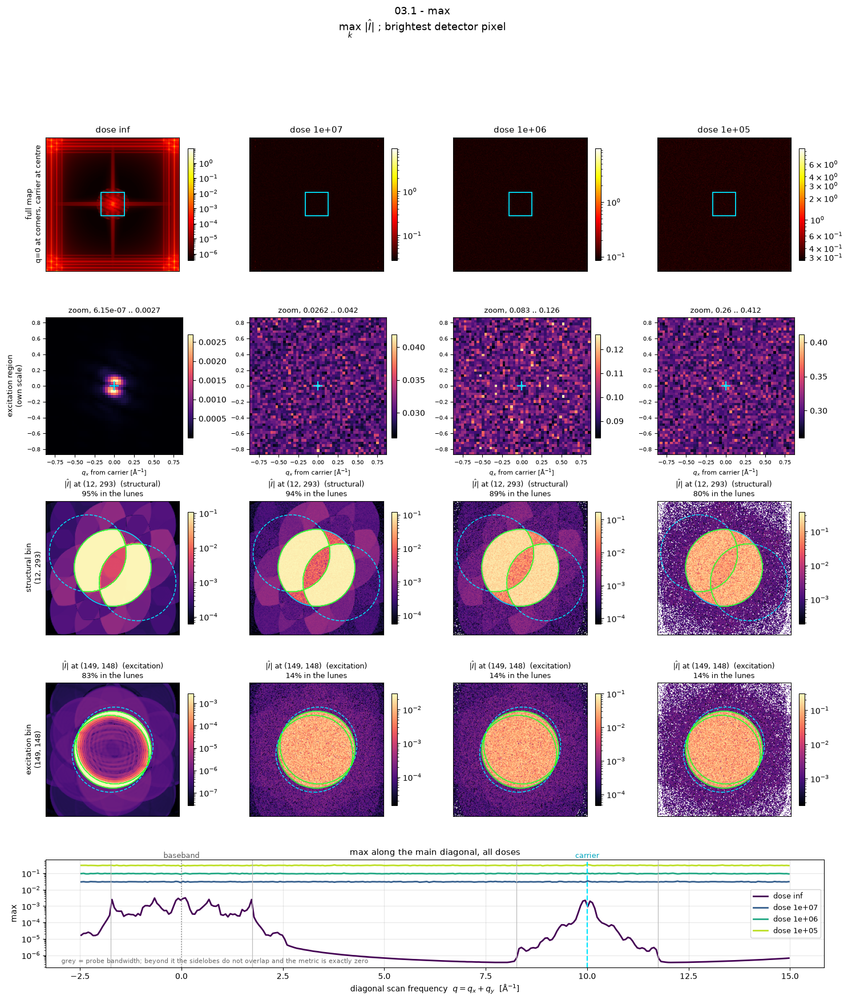

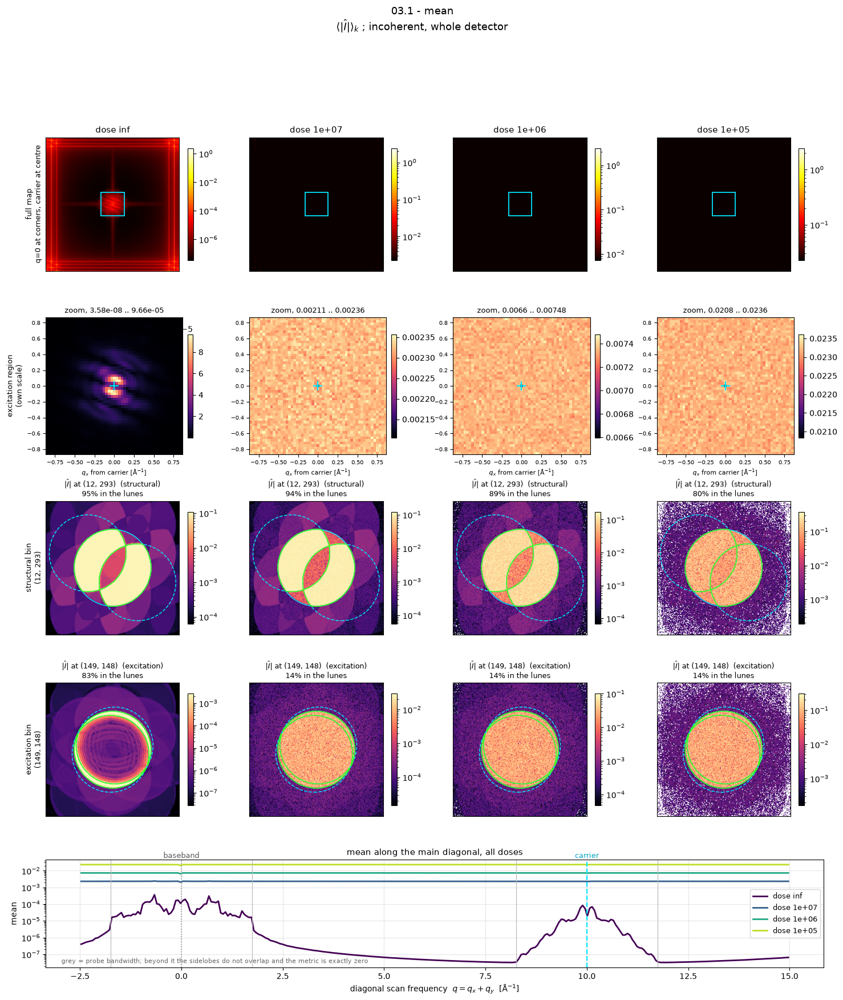

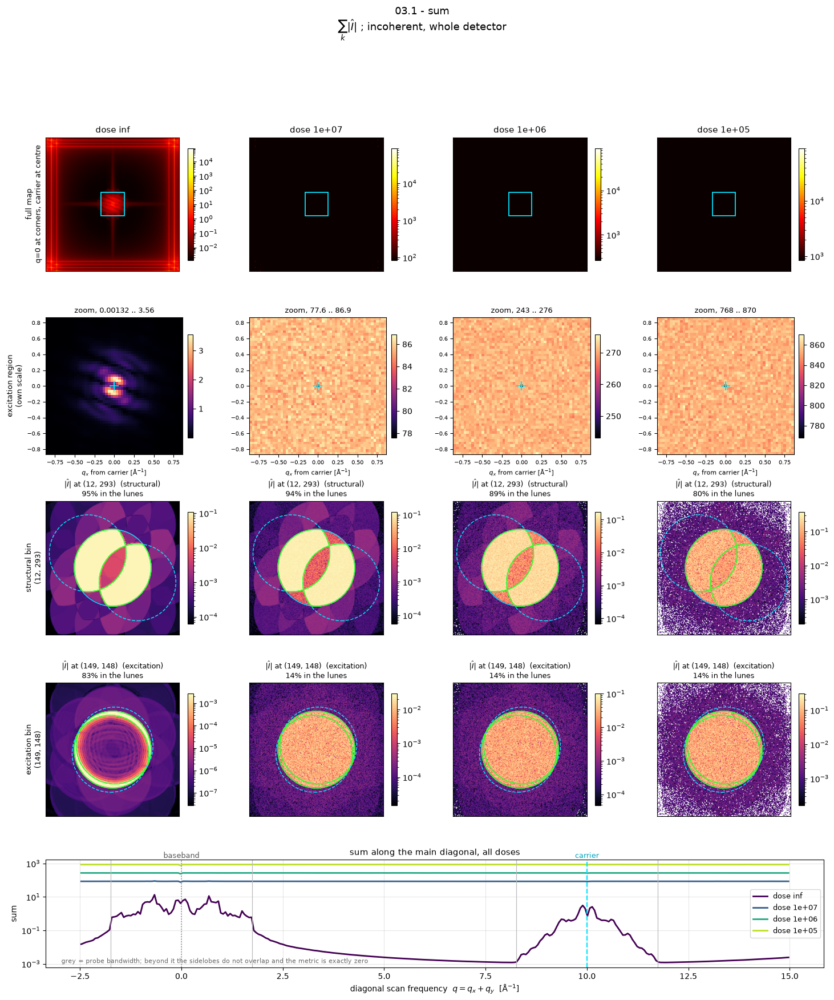

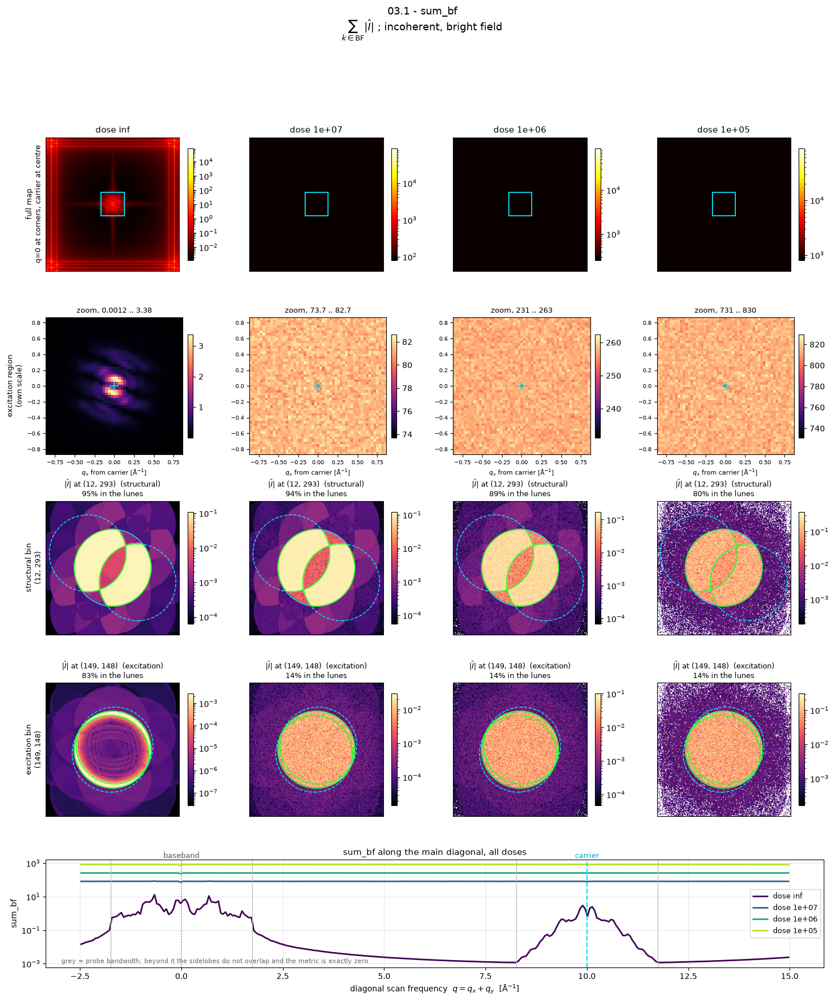

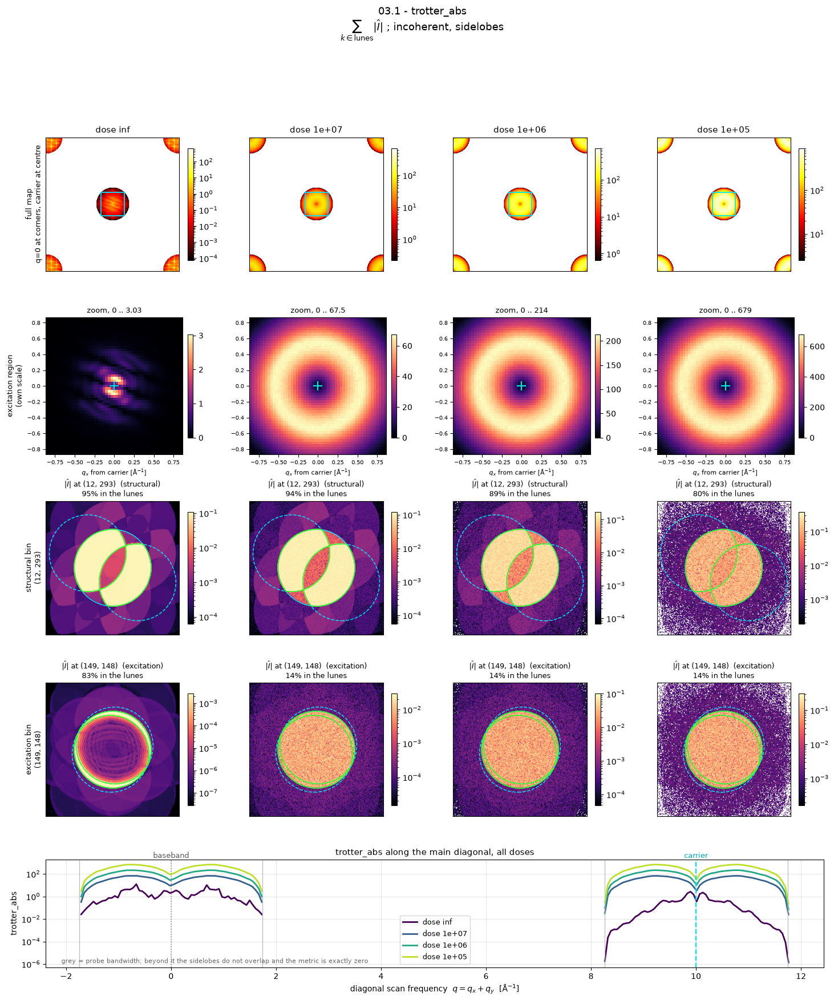

...

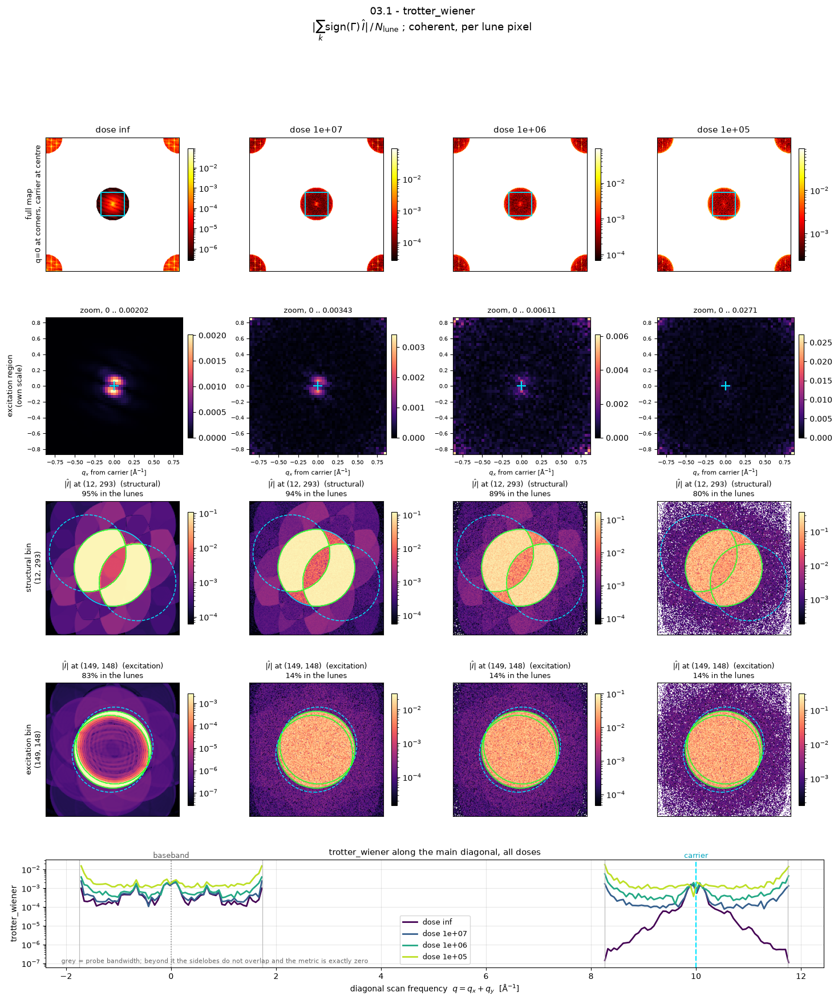

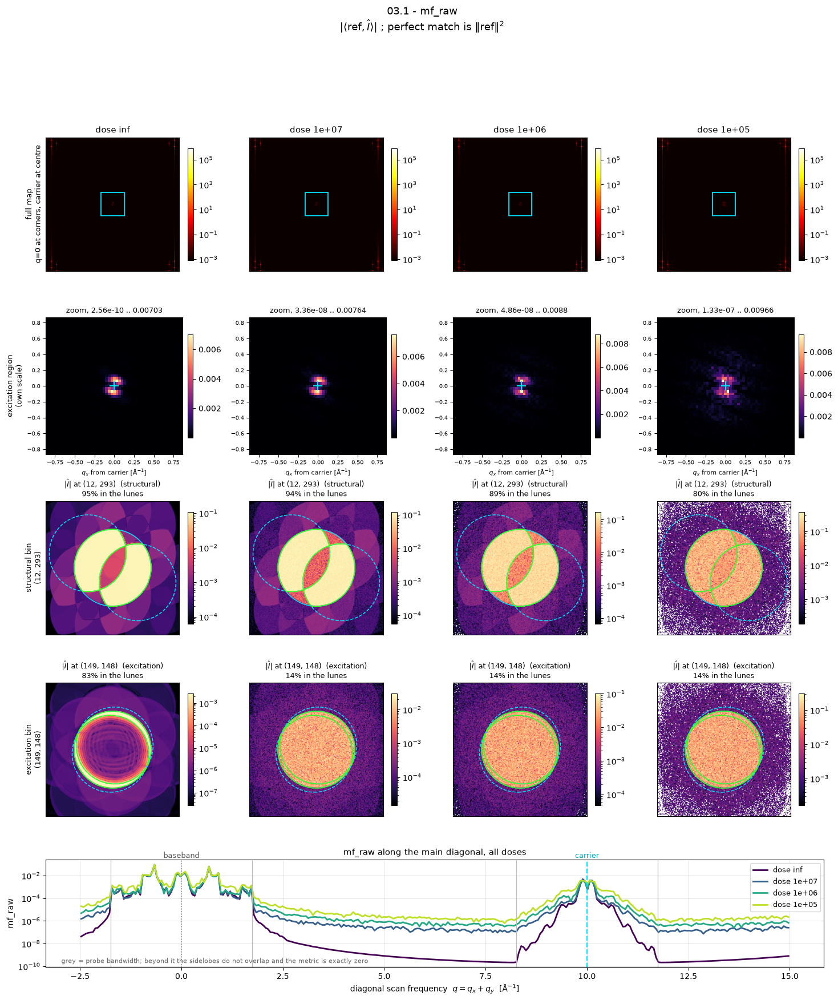

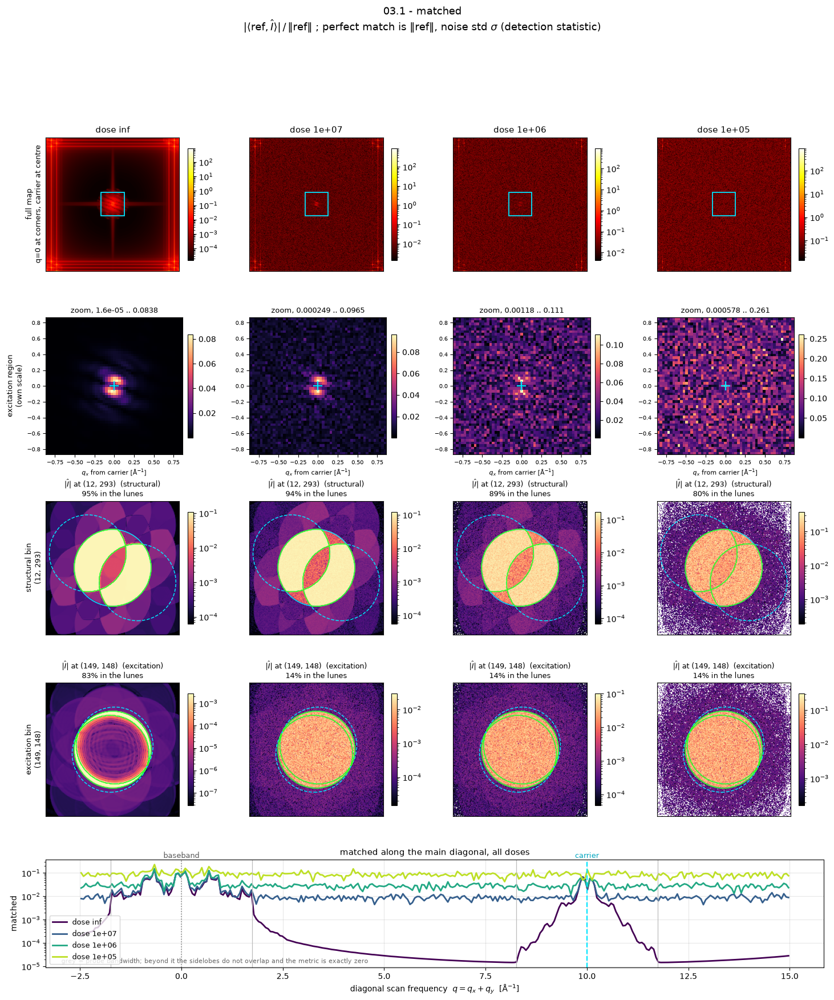

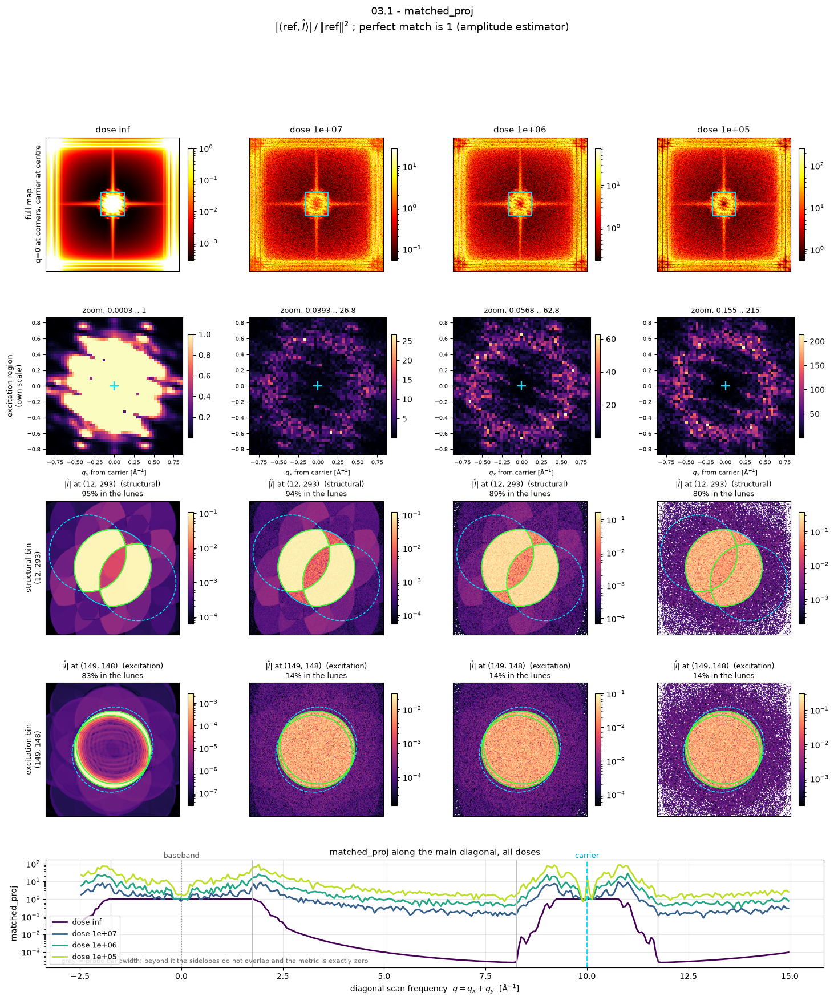

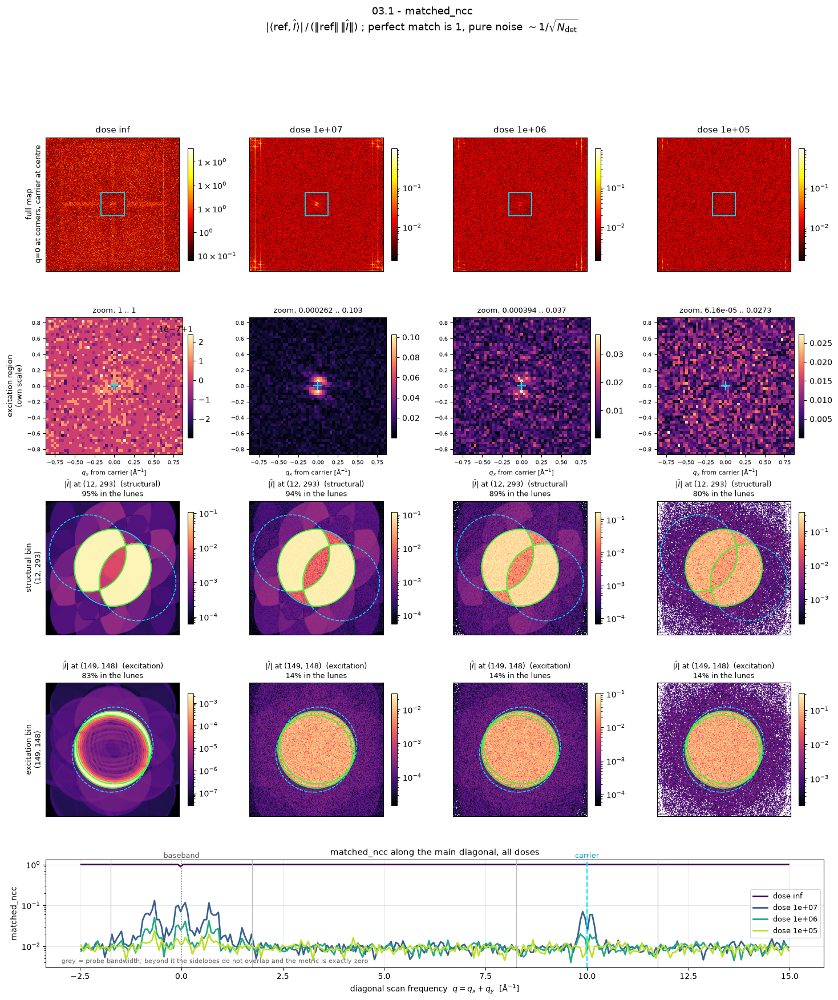

In [7]:
ZOOM = 26          # half-width, in bins, of the excitation zoom
STRIP = 3          # half-width of the diagonal strip, in bins
q_s = 1.0 / scan_step                       # the diagonal coordinate of the carrier


def disc_overlay(ax, loc):
    """The three discs and the double-overlap contour for one scan frequency."""
    q = np.array([QX_eff[loc], QY_eff[loc]])
    s = q * WAVELENGTH * 1e3
    d0 = np.hypot(KX_np, KY_np) <= ALPHA_MRAD
    dp = np.hypot(KX_np - s[0], KY_np - s[1]) <= ALPHA_MRAD
    dm = np.hypot(KX_np + s[0], KY_np + s[1]) <= ALPHA_MRAD
    trot = (d0 & dp & ~dm) | (d0 & dm & ~dp)
    for centre, ls in (((0, 0), "-"), (tuple(s), "--"), (tuple(-s), "--")):
        ax.add_patch(Circle(centre, ALPHA_MRAD, fill=False, ec="#00e5ff", lw=1.1, ls=ls))
    ax.contour(KX_np, KY_np, trot.astype(float), levels=[0.5], colors="#39ff14",
               linewidths=1.1)
    return trot


# On the main diagonal q_x = q_y, so |q_eff| = |q| / sqrt(2). The probe bandwidth
# therefore cuts the profile off at |q - hump| = sqrt(2) * BANDWIDTH, and OUTSIDE that
# every sidelobe metric is identically zero -- there is no aperture overlap to sum over.
# Those zeros are real, not missing data, but on a log axis they draw as a cliff to
# nothing, so they are turned into NaN and the bandwidth edge is marked instead.
DIAG_BW = np.sqrt(2) * BANDWIDTH
DIAG_VALLEY = (np.sqrt(2) * 0.40, np.sqrt(2) * 1.00)   # inside the bandwidth, off-signal


def diagonal_profile(m, nbins=301, drop_dc=True):
    """Collapse a map onto q = q_x + q_y along the main diagonal strip.
    Baseband lands at q = 0 and the interlacing carrier at q = q_s = 1/step."""
    mm = m
    if drop_dc:
        # Q = 0 is the mean intensity and is orders of magnitude above everything else;
        # left in, it sets the colour/axis scale and hides both humps.
        mm = m.copy()
        mm[0, 0] = 0.0
    strip = np.abs(QX_main - QY_main) / np.sqrt(2) <= STRIP * dQ
    qd = np.mod(QX_main + QY_main, 2 * q_s)[strip]
    vals = mm[strip]
    qq = np.concatenate([qd - 2 * q_s, qd])
    vv = np.tile(vals, 2)
    edges = np.linspace(-0.25 * q_s, 1.5 * q_s, nbins)
    prof = binned_statistic(qq, vv, statistic="mean", bins=edges).statistic
    prof = np.where(np.isfinite(prof) & (prof > 0), prof, np.nan)
    return 0.5 * (edges[:-1] + edges[1:]), prof


def diag_valley(q_plot, prof, hump):
    """Median of the profile in a band that is inside the bandwidth but off-signal.
    Normalising by the far field instead would divide by zero for every sidelobe
    metric, which is what silently dropped three curves from an earlier version."""
    d = np.abs(q_plot - hump)
    band = (d >= DIAG_VALLEY[0]) & (d <= DIAG_VALLEY[1])
    v = np.nanmedian(prof[band]) if band.any() else np.nan
    return v if np.isfinite(v) and v > 0 else np.nan


ci, cj = CARRIER_IDX
SL = (slice(ci - ZOOM, ci + ZOOM + 1), slice(cj - ZOOM, cj + ZOOM + 1))
ext_det = [q_axis_mrad[0], q_axis_mrad[-1]] * 2
colours = plt.cm.viridis(np.linspace(0, 0.9, len(DOSES)))

for metric in PLOT_METRICS:
    fig = plt.figure(figsize=(4.4 * len(DOSES), 19.0))
    gs = fig.add_gridspec(5, len(DOSES), height_ratios=[1, 1, 1, 1, 0.75],
                          hspace=0.28, wspace=0.22)

    for col, _dose in enumerate(DOSES):
        lab = dose_label(_dose)
        m = MAPS[lab]["interlaced"][metric]

        # row 1 - the whole map, unshifted
        ax = fig.add_subplot(gs[0, col])
        pos = m[m > 0]
        nrm = (LogNorm(vmin=max(np.percentile(pos, 2), m.max() * 1e-9), vmax=m.max())
               if pos.size else None)
        im = ax.imshow(m.T, origin="lower", cmap="hot", norm=nrm)
        ax.add_patch(Rectangle((SL[0].start, SL[1].start), 2 * ZOOM, 2 * ZOOM,
                               fill=False, ec="#00e5ff", lw=1.3))
        ax.set_title(f"dose {lab}", fontsize=11)
        ax.set_xticks([]); ax.set_yticks([])
        if col == 0:
            ax.set_ylabel("full map\nq=0 at corners, carrier at centre", fontsize=9)
        fig.colorbar(im, ax=ax, shrink=0.78)

        # row 2 - zoom on the excitation, own scale per panel
        ax = fig.add_subplot(gs[1, col])
        z = m[SL]
        im = ax.imshow(z.T, origin="lower", cmap="magma",
                       extent=[-ZOOM * dQ, ZOOM * dQ, -ZOOM * dQ, ZOOM * dQ])
        ax.plot(0, 0, "+", color="#00e5ff", ms=11, mew=1.6)
        ax.set_title(f"zoom, {z.min():.3g} .. {z.max():.3g}", fontsize=9)
        ax.set_xlabel(r"$q_x$ from carrier [$\mathrm{\AA^{-1}}$]", fontsize=8)
        ax.tick_params(labelsize=7)
        if col == 0:
            ax.set_ylabel("excitation region\n(own scale)", fontsize=9)
        fig.colorbar(im, ax=ax, shrink=0.72, pad=0.03)

        # rows 3, 4 - example detector planes
        for row, (loc, tag) in enumerate(((LOC_BASE, "structural"),
                                          (LOC_EXC, "excitation")), start=2):
            ax = fig.add_subplot(gs[row, col])
            img = np.abs(PLANES[lab][loc])
            # Log scale on purpose: NOTHING is masked here, but the bright-field disc is
            # ~100x the dark field, so on a linear scale everything outside the aperture
            # renders as black and looks zeroed. It is not - it is second-order
            # scattering plus, at finite dose, shot noise, and it is worth seeing.
            pos = img[img > 0]
            nrm = (LogNorm(vmin=max(np.percentile(pos, 1), img.max() * 1e-5),
                           vmax=img.max()) if pos.size else None)
            im = ax.imshow(img.T, origin="lower", cmap="magma", extent=ext_det, norm=nrm)
            trot = disc_overlay(ax, loc)
            frac = img[trot].sum() / max(img.sum(), 1e-30)
            ax.set_title(f"$|\\hat I|$ at {loc}  ({tag})\n{100*frac:.0f}% in the lunes",
                         fontsize=9)
            ax.set_xticks([]); ax.set_yticks([])
            if col == 0:
                ax.set_ylabel(f"{tag} bin\n{loc}", fontsize=9)
            fig.colorbar(im, ax=ax, shrink=0.78)

    # row 5 - one axis across all four columns
    ax = fig.add_subplot(gs[4, :])
    for colour, _dose in zip(colours, DOSES):
        lab = dose_label(_dose)
        q_plot, prof = diagonal_profile(MAPS[lab]["interlaced"][metric])
        ax.plot(q_plot, prof, lw=2.0, color=colour, label=f"dose {lab}")
    ax.axvline(0.0, color="#888", ls=":", lw=1.2)
    ax.axvline(q_s, color="#00e5ff", ls="--", lw=1.6)
    for hump in (0.0, q_s):
        for sgn in (-1, 1):
            ax.axvline(hump + sgn * DIAG_BW, color="#bbb", ls="-", lw=0.9)
    ax.annotate("baseband", (0.0, 1.0), xycoords=("data", "axes fraction"),
                ha="center", va="bottom", fontsize=9, color="#555")
    ax.annotate("carrier", (q_s, 1.0), xycoords=("data", "axes fraction"),
                ha="center", va="bottom", fontsize=9, color="#00a5bf")
    ax.annotate(r"grey = probe bandwidth; beyond it the sidelobes do not overlap "
                "and the metric is exactly zero", (0.02, 0.04), xycoords="axes fraction",
                fontsize=8, color="#666")
    ax.set_yscale("log")
    ax.set_xlabel(r"diagonal scan frequency  $q = q_x + q_y$  [$\mathrm{\AA^{-1}}$]")
    ax.set_ylabel(metric)
    ax.set_title(f"{metric} along the main diagonal, all doses", fontsize=11)
    ax.grid(alpha=0.3); ax.legend(fontsize=9)

    fig.suptitle(f"03.1 - {metric}\n{METRIC_TITLES[metric]}", fontsize=13, y=0.997)
    plt.show()


## Summary: every metric on one axis

The same diagonal cross-section, all metrics together, each normalised to its own value
in the empty valley between the two humps so they can share an axis. The spread between
the curves at the carrier **is** the result: same data, same transform, different
reduction over the detector.


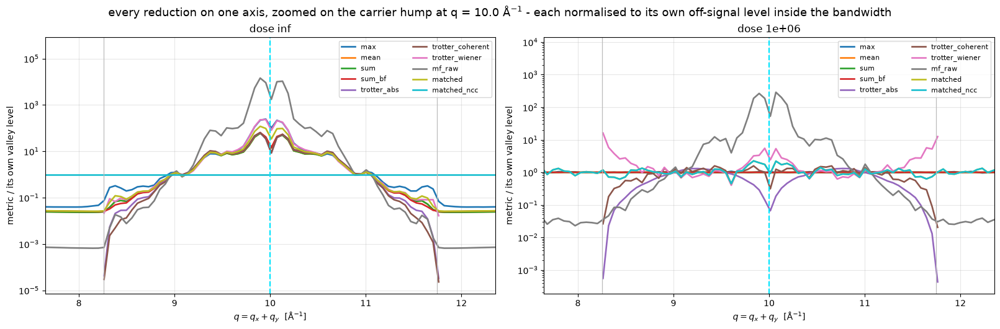

In [8]:
SUMMARY_DOSE = "1e+06"

fig, axes = plt.subplots(1, 2, figsize=(16.0, 5.2), constrained_layout=True)
for ax, lab in zip(axes, ["inf", SUMMARY_DOSE]):
    for metric in PLOT_METRICS:
        if metric in NOT_A_CONTRAST:
            continue
        q_plot, prof = diagonal_profile(MAPS[lab]["interlaced"][metric])
        valley = diag_valley(q_plot, prof, q_s)
        if not np.isfinite(valley):
            print(f"  [{lab}] {metric}: no valley reference, skipped")
            continue
        ax.plot(q_plot, prof / valley, lw=1.9, label=metric)
    ax.axvline(0.0, color="#888", ls=":", lw=1.2)
    ax.axvline(q_s, color="#00e5ff", ls="--", lw=1.6)
    for sgn in (-1, 1):
        ax.axvline(q_s + sgn * DIAG_BW, color="#bbb", lw=0.9)
    ax.set_xlim(q_s - 1.35 * DIAG_BW, q_s + 1.35 * DIAG_BW)
    ax.set_yscale("log")
    ax.set_xlabel(r"$q = q_x + q_y$  [$\mathrm{\AA^{-1}}$]")
    ax.set_ylabel("metric / its own valley level")
    ax.set_title(f"dose {lab}", fontsize=12)
    ax.grid(alpha=0.3); ax.legend(fontsize=8, ncol=2)
fig.suptitle("every reduction on one axis, zoomed on the carrier hump at "
             f"q = {q_s:.1f} " + r"$\mathrm{\AA^{-1}}$" + " - each normalised to its own "
             "off-signal level inside the bandwidth", fontsize=13)
plt.show()


## The statistics

A single number per metric, now that the figures have shown what the maps look like: the
mean over the excitation's band against the median of the valley beside it - inside the
probe bandwidth, outside the excitation's band, which at finite dose is the shot-noise
floor. `--` means the metric is identically zero in the valley, which is a statistic with
no reference rather than a contrast of zero.


In [9]:
Q_RING = (0.03, 0.15)        # 1/A from the carrier - 95% of this delta phi's energy
Q_VALLEY = (0.40, 1.00)      # inside the bandwidth, outside the excitation's band
RING = (R_car >= Q_RING[0]) & (R_car <= Q_RING[1])
VALLEY = (R_eff >= Q_VALLEY[0]) & (R_eff <= Q_VALLEY[1])
print(f"ring {Q_RING} holds {int(RING.sum())} bins; "
      f"valley {Q_VALLEY} holds {int(VALLEY.sum())} bins")


def ring_contrast(m):
    ref = float(np.median(m[VALLEY]))
    return float(m[RING].mean() / ref) if np.isfinite(ref) and ref > 0 else float("nan")


def _fmt(v, w):
    return f"{'--':>{w}s}" if not np.isfinite(v) else f"{v:>{w}.3g}"


print(f"\n{'metric':>18s} | " + " | ".join(f"{dose_label(d):>24s}" for d in DOSES))
print(f"{'':>18s} | " + " | ".join(f"{'off':>7s}{'on':>7s}{'INTER':>9s} " for d in DOSES))
print("-" * (20 + 27 * len(DOSES)))
for name in PLOT_METRICS:
    cells = []
    for _dose in DOSES:
        lab = dose_label(_dose)
        cells.append("".join(_fmt(ring_contrast(MAPS[lab][c][name]),
                                  7 if c != "interlaced" else 9)
                             for c in ("base", "excited", "interlaced")) + " ")
    star = " *" if name in NOT_A_CONTRAST else "  "
    print(f"{name:>16s}{star} | " + " | ".join(cells))
print("-" * (20 + 27 * len(DOSES)))
print("* matched_proj is 0/0 wherever the reference vanishes, so its valley is not a\n"
      "  noise level and this ratio should not be read as a contrast - use its map.")
print("off and on are the control: not interlaced, so no carrier. Anything far from 1\n"
      "there is leakage, not signal. The spread DOWN each column is the result.")

with open(RESULTS_DIR / "031_metric_sweep.json", "w") as handle:
    json.dump({"prefix": PREFIX, "overrides": OVERRIDES, "scan_step_ang": scan_step,
               "carrier_index": list(CARRIER_IDX), "loc_base": list(LOC_BASE),
               "loc_exc": list(LOC_EXC), "q_ring": list(Q_RING),
               "q_valley": list(Q_VALLEY), "layout": "unshifted; no fftshift or roll",
               "ring_contrast": {dose_label(d): {
                   c: {n: ring_contrast(MAPS[dose_label(d)][c][n])
                       for n in PLOT_METRICS}
                   for c in ("base", "excited", "interlaced")} for d in DOSES}},
              handle, indent=2)
print("\nwrote 031_metric_sweep.json")


ring (0.03, 0.15) holds 68 bins; valley (0.4, 1.0) holds 4768 bins

            metric |                      inf |                    1e+07 |                    1e+06 |                    1e+05
                   |     off     on    INTER  |     off     on    INTER  |     off     on    INTER  |     off     on    INTER 
--------------------------------------------------------------------------------------------------------------------------------
             max   |  0.0315 0.0214     23.8  |   0.994   1.01     1.01  |    1.01  0.998        1  |       1   1.01     1.02 
            mean   |  0.0399 0.0347     9.83  |   0.999      1        1  |   0.999  0.999        1  |   0.999      1        1 
             sum   |  0.0399 0.0347     9.83  |   0.999      1        1  |   0.999  0.999        1  |   0.999      1        1 
          sum_bf   |  0.0423 0.0371       10  |   0.999      1        1  |   0.999  0.999        1  |   0.999      1        1 
     trotter_abs   |  0.0278 0.0268     1

---

# Manual section

Edited in place. Parameters at the top of each cell at global scope, arrays in globals,
nothing hidden behind a function that has to be re-read.


dose 1e+06  -  10,000 electrons per scan position


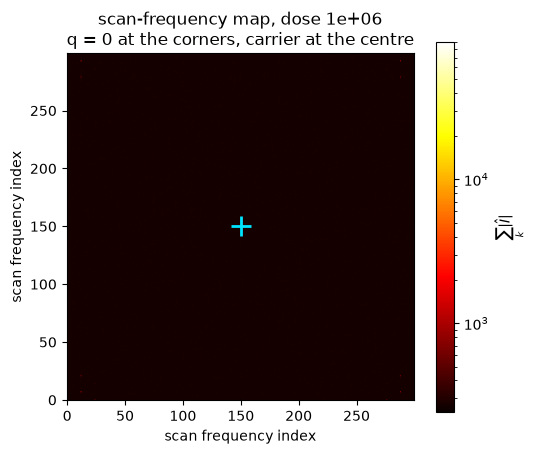

In [10]:
# ---- pick what to look at --------------------------------------------------------
DOSE = 1e6               # None | 1e7 | 1e6 | 1e5
# ---------------------------------------------------------------------------------
print(f"dose {dose_label(DOSE)}  -  "
      + (f"{DOSE*scan_step**2:,.0f} electrons per scan position" if DOSE else "noiseless"))

t0 = time.time()
freq_mag = MAPS[dose_label(DOSE)]["interlaced"]["sum"]
plt.figure(figsize=(5.6, 4.8))
plt.imshow(freq_mag.T, origin="lower", cmap="hot", norm=LogNorm())
plt.plot(CARRIER_IDX[1], CARRIER_IDX[0], "+", color="#00e5ff", ms=14, mew=2)
plt.colorbar(label=r"$\sum_k |\hat I|$")
plt.title(f"scan-frequency map, dose {dose_label(DOSE)}\n"
          "q = 0 at the corners, carrier at the centre")
plt.xlabel("scan frequency index"); plt.ylabel("scan frequency index")
plt.show()


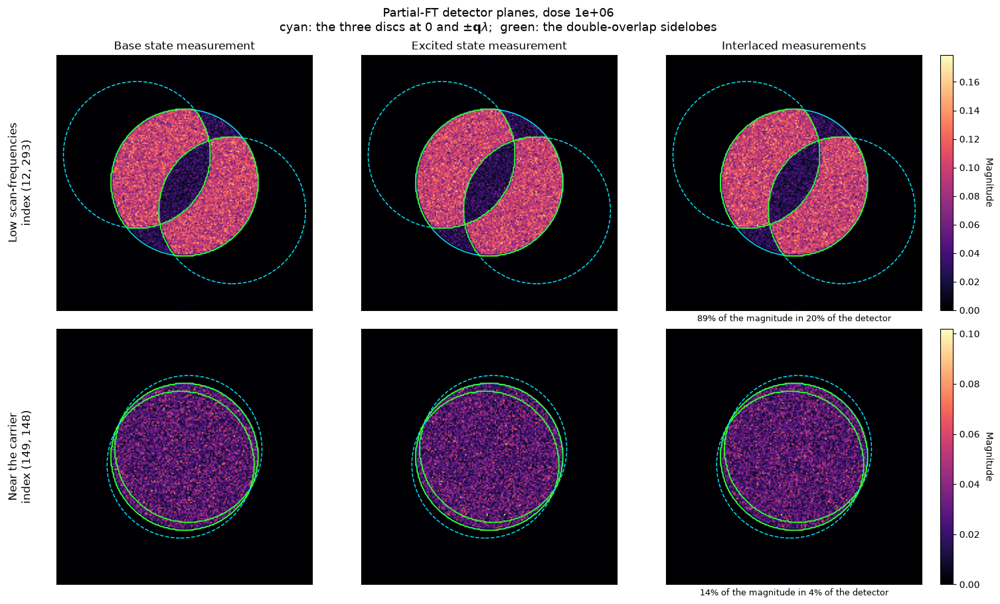

In [11]:
# ---- which scan frequencies -----------------------------------------------------
loc_low_f = LOC_BASE
loc_high_f = LOC_EXC
# ---------------------------------------------------------------------------------
lab = dose_label(DOSE)
base_partial_ft = ft_at(measured("base", DOSE), [loc_low_f, loc_high_f])
excited_partial_ft = ft_at(measured("excited", DOSE), [loc_low_f, loc_high_f])
merged_partial_ft = ft_at(measured("interlaced", DOSE), [loc_low_f, loc_high_f])

low_imgs = [np.abs(base_partial_ft[loc_low_f]), np.abs(excited_partial_ft[loc_low_f]),
            np.abs(merged_partial_ft[loc_low_f])]
high_imgs = [np.abs(base_partial_ft[loc_high_f]), np.abs(excited_partial_ft[loc_high_f]),
             np.abs(merged_partial_ft[loc_high_f])]
imgs = [low_imgs, high_imgs]
locs = [loc_low_f, loc_high_f]
col_titles = ["Base state measurement", "Excited state measurement",
              "Interlaced measurements"]
row_titles = ["Low scan-frequencies", "Near the carrier"]

fig, axs = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
for row in range(2):
    row_vmin = min(im.min() for im in imgs[row])
    row_vmax = max(im.max() for im in imgs[row])
    ims = []
    for col in range(3):
        ax = axs[row, col]
        im = ax.imshow(imgs[row][col].T, cmap="magma", origin="lower", extent=ext_det,
                       vmin=row_vmin, vmax=row_vmax)
        ims.append(im)
        trot = disc_overlay(ax, locs[row])
        ax.set_xticks([]); ax.set_yticks([])
        if row == 0:
            ax.set_title(col_titles[col], fontsize=12)
        if col == 2:
            ax.set_xlabel(f"{100*imgs[row][col][trot].sum()/imgs[row][col].sum():.0f}% "
                          f"of the magnitude in {100*trot.mean():.0f}% of the detector",
                          fontsize=9)
    axs[row, 0].set_ylabel(f"{row_titles[row]}\nindex {locs[row]}", fontsize=12,
                           labelpad=25)
    cbar = fig.colorbar(ims[-1], ax=axs[row, :], location="right", fraction=0.025,
                        pad=0.02)
    cbar.set_label("Magnitude", rotation=270, labelpad=15)
fig.suptitle(f"Partial-FT detector planes, dose {dose_label(DOSE)}\n"
             r"cyan: the three discs at 0 and $\pm\mathbf{q}\lambda$;  "
             "green: the double-overlap sidelobes", fontsize=13)
plt.show()


## What to read off

* **Row 1 of each metric figure.** The excitation is the blob at the centre. At infinite
  dose every reduction finds it; the question is which ones still have it at $10^6$.
* **Row 2.** The zoom is on its own scale precisely so that "flat noise" and "a blob at
  the middle" look different even when the blob is 1% above the floor.
* **Rows 3 and 4.** The crescents must sit inside the cyan circles. The percentage printed
  is the whole argument for sidelobe weighting in one number - and the structural bin and
  the excitation bin should show the *same* geometry, because the sidelobes depend only on
  the object frequency, which is what the per-bin assignment at the top of this notebook
  is for.
* **Row 5 and the summary.** Two humps: baseband at $q = 0$, carrier at $q = 1/\Delta$.
  The height of the carrier hump above the valley between them is the detectability, and
  the difference between the metrics at that point is the cost of choosing the wrong
  reduction.
